In [8]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

data = pd.read_csv(r'C:\Users\ketan\OneDrive\Documents\DSBA M2\Marketing Analytics\Group Project\Data\arla_protein_mmm_weekly (1).csv')
print(data.head())
print(data.isnull().sum())

     week_beg  sales_units  avg_price    revenue  price_promo        tv  \
0  2022-01-03       835343       0.93   776869.0            1  289815.0   
1  2022-01-10       746821       1.09   814035.0            1  214368.0   
2  2022-01-17       995265       1.36  1353560.0            0  245193.0   
3  2022-01-24       792130       1.34  1061454.0            0  193420.0   
4  2022-01-31       647791       1.35   874518.0            0  191732.0   

   instagram   tiktok  influencer  pos_promotion  
0    21672.0  18525.0     20130.0        33731.0  
1    23573.0  14835.0     19822.0        26029.0  
2    23536.0  20487.0     25963.0        30095.0  
3    29346.0  19723.0     15144.0        18873.0  
4    22011.0  14914.0     19380.0        27649.0  
week_beg         0
sales_units      0
avg_price        0
revenue          0
price_promo      0
tv               0
instagram        0
tiktok           0
influencer       0
pos_promotion    0
dtype: int64


In [17]:
''' Log-log multivariate OLS regression w/ lagged sales '''

log_cols = ['sales_units', 'avg_price', 'revenue', 'tv', 'instagram', 'tiktok', 'influencer', 'pos_promotion'] # Take logs of both y and X variables for log-log regression
print((data[log_cols] <= 0).sum())

df = data.copy()
df[log_cols] = np.log1p(df[log_cols]) # log1p to protect against any zeroes (tv)
df['lagged_sales'] = df['sales_units'].shift(1)

model = smf.ols(formula='sales_units ~ lagged_sales + avg_price + price_promo + tv + instagram + tiktok + influencer + pos_promotion', data=df).fit()
# Can't include revenue, there is will almost be a one-to-one relationship with sales_units (endogeneity)
print(model.summary())

sales_units        0
avg_price          0
revenue            0
tv               115
instagram          0
tiktok             0
influencer         0
pos_promotion      0
dtype: int64
                            OLS Regression Results                            
Dep. Variable:            sales_units   R-squared:                       0.930
Model:                            OLS   Adj. R-squared:                  0.926
Method:                 Least Squares   F-statistic:                     241.3
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           3.85e-80
Time:                        19:01:04   Log-Likelihood:                 184.33
No. Observations:                 155   AIC:                            -350.7
Df Residuals:                     146   BIC:                            -323.3
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                    coef    s

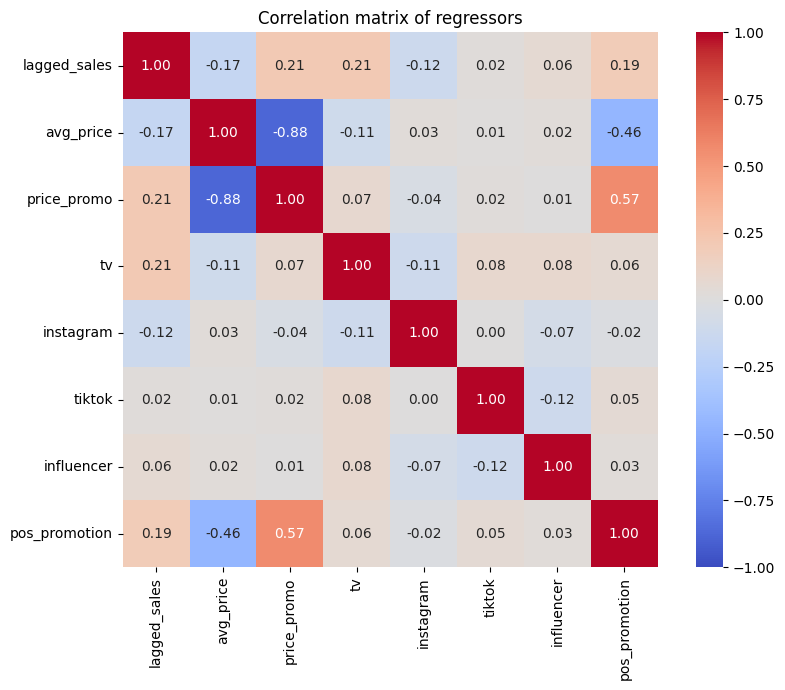

In [33]:
''' Correlation matrix of X variables '''
import seaborn as sns
import matplotlib.pyplot as plt

x_cols = ['lagged_sales', 'avg_price', 'price_promo', 'tv', 'instagram',
          'tiktok', 'influencer', 'pos_promotion']

corr = df[x_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation matrix of regressors')
plt.tight_layout()
plt.show()

In [37]:
''' Refit without price_promo (too much influence on avg_price, multicollinearity)'''

model_clean = smf.ols(formula='sales_units ~ lagged_sales + avg_price + tv + instagram + tiktok + influencer + pos_promotion', data=df).fit()
# Can't include revenue, there is will almost be a one-to-one relationship with sales_units (endogeneity)
print(model_clean.summary())

                            OLS Regression Results                            
Dep. Variable:            sales_units   R-squared:                       0.921
Model:                            OLS   Adj. R-squared:                  0.917
Method:                 Least Squares   F-statistic:                     243.8
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.51e-77
Time:                        19:38:06   Log-Likelihood:                 175.00
No. Observations:                 155   AIC:                            -334.0
Df Residuals:                     147   BIC:                            -309.7
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -9.3032      0.786    -11.831

In [44]:
''' Now the unit effect of the X variables will be examined '''

media_cols = ['tv', 'instagram', 'tiktok', 'influencer', 'pos_promotion'] # These are the variables the company spends money on to increase sales

y_bar = data['sales_units'].mean()   # original data, not logged df
unit_effects = {}
for col in media_cols:
    beta = model_clean.params[col]
    x_bar = data[col].mean()
    unit_effects[col] = (beta * y_bar / x_bar).round(2)

print('Numeric X variable unit effects:\n', pd.Series(unit_effects, name='unit_effect'))


Numeric X variable unit effects:
 tv                0.17
instagram         9.63
tiktok           10.16
influencer       22.80
pos_promotion     3.76
Name: unit_effect, dtype: float64


In [43]:
''' Clearly, avg_price needs to have its unit effect calculated differently as the scaling is completely different '''
price_ue = unit_effects['avg_price']

per_cent = price_ue / 100   # units lost per 1-cent price increase
per_10c  = price_ue / 10    # per 10-cent increase
per_1pct = model_clean.params['avg_price'] * y_bar / 100   # per 1% price increase

print('units lost per 1-cent price increase', per_cent.round(2))
print('units lost per 10-cent price increase', per_10c.round(2))
print('units lost per 1 pct price increase', per_1pct.round(2))

eps = model_clean.params['avg_price']
revenue_effect_per_euro = y_bar * (1 + eps)   # revenue change per €1 price change, at the means

print('revenue change per €1 price change (at the means)', revenue_effect_per_euro.round(2))

units lost per 1-cent price increase -2497.77
units lost per 10-cent price increase -24977.72
units lost per 1 pct price increase -3440.04
revenue change per €1 price change (at the means) 294493.92


In [49]:
import plotly.express as px

price_effects = pd.DataFrame({
    'scenario': ['+1 cent', '+10 cents', '+1%'],
    'units_change': [per_cent, per_10c, per_1pct],
})

fig = px.bar(
    price_effects,
    x='scenario',
    y='units_change',
    text=price_effects['units_change'].round(1),
    title='Change in sales units from a price increase',
    labels={'scenario': '', 'units_change': 'Change in sales units (per period)'},
)
fig.update_traces(marker_color='#E07A5F', textposition='outside')
fig.add_hline(y=0, line_color='grey')
fig.update_layout(template='simple_white')
fig.show()

In [ ]:
''' With the unit effects, the contributions and ROI of each media-related variable can be calculated '''

avg_unit_price = data['revenue'].sum() / data['sales_units'].sum()

contributions = {}
roi = {}
for key, value in unit_effects.items():
    if key not in media_cols:      # skip avg_price: not a spend instrument
        continue
    total_spend = data[key].sum()
    contributions[key] = value * total_spend
    roi[key] = contributions[key] * avg_unit_price / total_spend # We want to avoid making unit effect and ROI the exact same number (using revenue)

print('Contributions (sales units):\n', pd.Series(contributions).round(0))
print('\nROI (revenue € per € spent):\n', pd.Series(roi).round(2))

Contributions (sales units):
 tv                1632000.0
instagram        34668019.0
tiktok           29260841.0
influencer       71135954.0
pos_promotion    18047989.0
dtype: float64

ROI (revenue € per € spent):
 tv                0.23
instagram        13.09
tiktok           13.81
influencer       30.98
pos_promotion     5.11
dtype: float64


In [48]:
''' Visualization '''
from plotly.subplots import make_subplots
import plotly.graph_objects as go

summary = pd.DataFrame({'contribution': contributions, 'roi': roi}).sort_values('roi', ascending=False)
labels = summary.index.str.replace('_', ' ').str.title()

fig = make_subplots(rows=1, cols=2, subplot_titles=('Contribution (sales units)', 'ROI (€ per € spent)'))
fig.add_trace(go.Bar(x=labels, y=summary['contribution'], marker_color='#6C757D', showlegend=False), row=1, col=1)
fig.add_trace(go.Bar(x=labels, y=summary['roi'], marker_color='#2E86AB', showlegend=False), row=1, col=2)
fig.add_hline(y=1, line_dash='dash', line_color='grey', row=1, col=2)

fig.update_layout(template='simple_white', title='Media contribution vs. return on investment', height=450)
fig.show()